## Setup and data

In [5]:
import os, json, time, zipfile, shutil, warnings
import numpy as np, pandas as pd, cv2
import matplotlib.pyplot as plt, seaborn as sns
import tensorflow as tf
from tensorflow import keras
from sklearn.metrics import accuracy_score, f1_score, precision_recall_fscore_support, confusion_matrix
from tqdm.auto import tqdm
from concurrent.futures import ThreadPoolExecutor
warnings.filterwarnings('ignore'); sns.set_theme(style='whitegrid')

SEED = 42; keras.utils.set_random_seed(SEED)
keras.mixed_precision.set_global_policy('mixed_float16')       # Same policy the models were trained with
gpus = tf.config.list_physical_devices('GPU'); print('TensorFlow', tf.__version__, '| GPUs:', gpus)

from google.colab import drive
drive.mount('/content/drive')
DRIVE_DIR = '/content/drive/MyDrive/SignSense_data'
WORK, PROC, OUT = '/content/work', '/content/processed', '/content/results'
for d in (WORK, OUT): os.makedirs(d, exist_ok=True)
for f in ['processed_metadata.csv', 'label_map.json']: shutil.copy(os.path.join(DRIVE_DIR, f), WORK)

meta = pd.read_csv(f'{WORK}/processed_metadata.csv')
imgs = meta[meta['media_type'] == 'image'].reset_index(drop=True); imgs['is_generated'] = imgs['is_generated'].astype(bool)
STATIC = json.load(open(f'{WORK}/label_map.json'))['static_classes']; K = len(STATIC)

def processed_ok(): return os.path.isdir(PROC) and all(os.path.exists(os.path.join(PROC, p)) for p in imgs['processed_path'])
if not processed_ok():
    zp = f'{DRIVE_DIR}/processed_images.zip'; assert os.path.exists(zp), 'processed_images.zip missing on Drive'
    shutil.copy(zp, '/content/processed_images.zip')
    with zipfile.ZipFile('/content/processed_images.zip') as z: z.extractall(PROC)
assert processed_ok()

def load_array(df):
    X = np.empty((len(df), 224, 224, 3), np.uint8); paths = [os.path.join(PROC, p) for p in df['processed_path']]
    def f(i): X[i] = cv2.cvtColor(cv2.imread(paths[i]), cv2.COLOR_BGR2RGB)
    with ThreadPoolExecutor(max_workers=8) as ex: list(tqdm(ex.map(f, range(len(df))), total=len(df)))
    return X

va_df = imgs[imgs['split'] == 'val'].reset_index(drop=True); te_df = imgs[imgs['split'] == 'test'].reset_index(drop=True)
X_va, y_va = load_array(va_df), va_df['class_id'].values.astype('int32')
X_te, y_te = load_array(te_df), te_df['class_id'].values.astype('int32')
va_orig, te_orig = ~va_df['is_generated'].values, ~te_df['is_generated'].values
subj_te = te_df['subject'].values
print('val', X_va.shape, '| test', X_te.shape, '| test originals:', int(te_orig.sum()), '| test subjects:', len(np.unique(subj_te)))

TensorFlow 2.21.0 | GPUs: []
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


  0%|          | 0/3060 [00:00<?, ?it/s]

  0%|          | 0/3238 [00:00<?, ?it/s]

val (3060, 224, 224, 3) | test (3238, 224, 224, 3) | test originals: 430 | test subjects: 12


## 1. Predictions, size and inference speed for each model

In [6]:
MODEL_FILES = {'Baseline CNN': 'baseline_cnn.keras', 'MobileNetV2': 'mobilenetv2.keras', 'EfficientNet-B0': 'efficientnetb0.keras'}
PV, PT, INFO = {}, {}, []

def predict(model, X):
    return np.concatenate([model.predict(X[i:i + 128].astype('float32'), verbose=0) for i in range(0, len(X), 128)])

def speed(model):
    fn = tf.function(lambda x: model(x, training=False))
    x1 = tf.constant(X_te[:1].astype('float32')); xb = tf.constant(X_te[:64].astype('float32'))
    for _ in range(10): fn(x1).numpy()
    t = time.time()
    for _ in range(100): fn(x1).numpy()
    lat = (time.time() - t) / 100 * 1000
    for _ in range(3): fn(xb).numpy()
    t = time.time()
    for _ in range(10): fn(xb).numpy()
    return lat, 640 / (time.time() - t)

for name, f in MODEL_FILES.items():
    path = f'{DRIVE_DIR}/models/{f}'; model = keras.models.load_model(path, compile=False)
    PV[name], PT[name] = predict(model, X_va), predict(model, X_te)
    lat, thr = speed(model)
    INFO.append({'model': name, 'params_M': round(model.count_params() / 1e6, 2), 'size_MB': round(os.path.getsize(path) / 1e6, 1),
                 'latency_ms_gpu_b1': round(lat, 1), 'throughput_img_s_gpu_b64': round(thr)})
    print(INFO[-1]); del model; keras.backend.clear_session()

# Simple ensemble: average of the three probability vectors (members fixed in advance, not chosen on test)
PV['Ensemble (3 models)'] = np.mean([PV[n] for n in MODEL_FILES], axis=0); PT['Ensemble (3 models)'] = np.mean([PT[n] for n in MODEL_FILES], axis=0)
info_df = pd.DataFrame(INFO); info_df

{'model': 'Baseline CNN', 'params_M': 1.03, 'size_MB': 20.7, 'latency_ms_gpu_b1': 116.4, 'throughput_img_s_gpu_b64': 7}
{'model': 'MobileNetV2', 'params_M': 2.3, 'size_MB': 26.5, 'latency_ms_gpu_b1': 47.0, 'throughput_img_s_gpu_b64': 21}
{'model': 'EfficientNet-B0', 'params_M': 4.1, 'size_MB': 33.9, 'latency_ms_gpu_b1': 75.2, 'throughput_img_s_gpu_b64': 13}


,model,params_M,size_MB,latency_ms_gpu_b1,throughput_img_s_gpu_b64
0,Baseline CNN,1.03,20.7,116.4,7
1,MobileNetV2,2.30,26.5,47.0,21
2,EfficientNet-B0,4.10,33.9,75.2,13


## 2. Metrics on validation and test

In [7]:
def metrics(P, y, mask=None):
    if mask is not None: P, y = P[mask], y[mask]
    p = P.argmax(1); pr, rc, f1, _ = precision_recall_fscore_support(y, p, average='macro', zero_division=0)
    return {'accuracy': accuracy_score(y, p), 'precision': pr, 'recall': rc, 'f1_macro': f1,
            'f1_weighted': f1_score(y, p, average='weighted'), 'top3': float((np.argsort(P, 1)[:, -3:] == y[:, None]).any(1).mean())}

rows = []
for name in PT:
    for split, P, y, om in [('val', PV[name], y_va, va_orig), ('test', PT[name], y_te, te_orig)]:
        rows.append({'model': name, 'split': split, 'subset': 'all', **metrics(P, y)})
        rows.append({'model': name, 'split': split, 'subset': 'originals only', **metrics(P, y, om)})
M = pd.DataFrame(rows)

SINGLE = list(MODEL_FILES)
PRIMARY = max(SINGLE, key=lambda n: M[(M.model == n) & (M.split == 'val') & (M.subset == 'all')]['f1_macro'].iloc[0])
print('PRIMARY model (best validation macro-F1):', PRIMARY)
print('\nTEST set, all images:'); display(M[(M.split == 'test') & (M.subset == 'all')].drop(columns=['split', 'subset']).round(4).reset_index(drop=True))
print('TEST set, original images only:'); display(M[(M.split == 'test') & (M.subset == 'originals only')].drop(columns=['split', 'subset']).round(4).reset_index(drop=True))
print('VALIDATION set, all images (for reference):'); display(M[(M.split == 'val') & (M.subset == 'all')].drop(columns=['split', 'subset']).round(4).reset_index(drop=True))

PRIMARY model (best validation macro-F1): MobileNetV2

TEST set, all images:


,model,accuracy,precision,recall,f1_macro,f1_weighted,top3
0,Baseline CNN,0.8051,0.8367,0.8011,0.8019,0.8046,0.9367
1,MobileNetV2,0.8740,0.8951,0.8728,0.8690,0.8723,0.9725
2,EfficientNet-B0,0.8548,0.8755,0.8544,0.8531,0.8562,0.9768
3,Ensemble (3 models),0.8984,0.9143,0.8977,0.8974,0.8998,0.9771


TEST set, original images only:


,model,accuracy,precision,recall,f1_macro,f1_weighted,top3
0,Baseline CNN,0.8558,0.8691,0.8559,0.8570,0.8570,0.9674
1,MobileNetV2,0.9070,0.9186,0.9072,0.9042,0.9040,0.9884
2,EfficientNet-B0,0.8953,0.9031,0.8958,0.8968,0.8963,0.9837
3,Ensemble (3 models),0.9302,0.9348,0.9303,0.9285,0.9284,0.9907


VALIDATION set, all images (for reference):


,model,accuracy,precision,recall,f1_macro,f1_weighted,top3
0,Baseline CNN,0.9278,0.9379,0.9298,0.9289,0.9274,0.9873
1,MobileNetV2,0.9324,0.9369,0.9312,0.9310,0.9313,0.9889
2,EfficientNet-B0,0.9092,0.9190,0.9092,0.9084,0.9083,0.9892
3,Ensemble (3 models),0.9507,0.9560,0.9514,0.9508,0.9496,0.9918


## 3. Are the differences between models real? (subject-level bootstrap)
The test set has only 12 people, and images of the same person are strongly correlated, so a plain image-level interval would be too narrow. We resample **people** with replacement 2,000 times and recompute accuracy for every model on the same resamples. If the interval of the *difference* between two models contains 0, we cannot call one better than the other.

,model,subset,accuracy,ci_low,ci_high
0,Baseline CNN,all,0.8051,0.6057,0.9350
1,Baseline CNN,originals only,0.8558,0.7720,0.9256
2,MobileNetV2,all,0.8740,0.8385,0.9165
3,MobileNetV2,originals only,0.9070,0.8721,0.9375
4,EfficientNet-B0,all,0.8548,0.8279,0.8834
5,EfficientNet-B0,originals only,0.8953,0.8721,0.9190
6,Ensemble (3 models),all,0.8984,0.8628,0.9463
7,Ensemble (3 models),originals only,0.9302,0.9070,0.9512


,comparison,subset,mean_diff,ci_low,ci_high,clearly_different
0,MobileNetV2 - Baseline CNN,all,0.0648,-0.0361,0.2399,False
1,MobileNetV2 - Baseline CNN,originals only,0.0508,-0.0023,0.1163,False
2,MobileNetV2 - EfficientNet-B0,all,0.0201,-0.0049,0.0491,False
3,MobileNetV2 - EfficientNet-B0,originals only,0.0115,-0.0186,0.0394,False
4,Baseline CNN - EfficientNet-B0,all,-0.0447,-0.2281,0.0698,False
5,Baseline CNN - EfficientNet-B0,originals only,-0.0393,-0.1134,0.0213,False
6,Ensemble (3 models) - MobileNetV2,all,0.0245,0.0080,0.0356,True
7,Ensemble (3 models) - MobileNetV2,originals only,0.0231,0.0023,0.0486,True


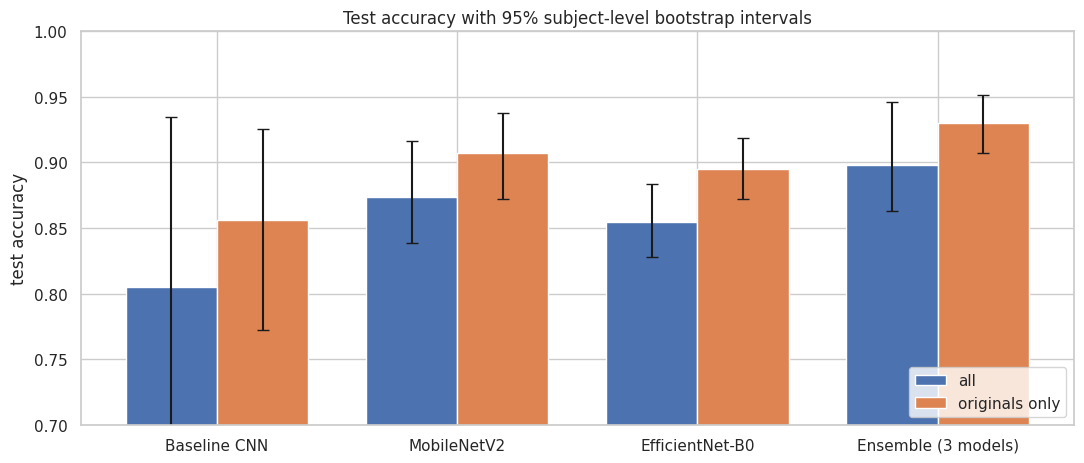

In [8]:
def cluster_boot(P_dict, y, subj, mask=None, B=2000, seed=0):
    keep = np.ones(len(y), bool) if mask is None else mask
    s, yy = subj[keep], y[keep]; subs, inv = np.unique(s, return_inverse=True); S = len(subs)
    n = np.bincount(inv, minlength=S).astype(float)
    cs = {m: np.bincount(inv, weights=(P[keep].argmax(1) == yy).astype(float), minlength=S) for m, P in P_dict.items()}
    idx = np.random.default_rng(seed).integers(0, S, (B, S))
    return {m: cs[m][idx].sum(1) / n[idx].sum(1) for m in cs}

def ci(a): return np.percentile(a, [2.5, 97.5])
boot_all = cluster_boot(PT, y_te, subj_te); boot_orig = cluster_boot(PT, y_te, subj_te, mask=te_orig)

ci_rows = []
for name in PT:
    for lab, b, om in [('all', boot_all, None), ('originals only', boot_orig, te_orig)]:
        lo, hi = ci(b[name]); acc = metrics(PT[name], y_te, om)['accuracy']
        ci_rows.append({'model': name, 'subset': lab, 'accuracy': acc, 'ci_low': lo, 'ci_high': hi})
CI = pd.DataFrame(ci_rows); display(CI.round(4))

pairs = [('MobileNetV2', 'Baseline CNN'), ('MobileNetV2', 'EfficientNet-B0'), ('Baseline CNN', 'EfficientNet-B0'), ('Ensemble (3 models)', PRIMARY)]
dr = []
for a, b in pairs:
    for lab, bt in [('all', boot_all), ('originals only', boot_orig)]:
        d = bt[a] - bt[b]; lo, hi = ci(d)
        dr.append({'comparison': f'{a} - {b}', 'subset': lab, 'mean_diff': d.mean(), 'ci_low': lo, 'ci_high': hi, 'clearly_different': bool(lo > 0 or hi < 0)})
DIFF = pd.DataFrame(dr); display(DIFF.round(4))

fig, ax = plt.subplots(figsize=(11, 4.8)); w = 0.38; xs = np.arange(len(PT))
for k, lab in enumerate(['all', 'originals only']):
    d = CI[CI.subset == lab].set_index('model').loc[list(PT)]
    ax.bar(xs + (k - .5) * w, d['accuracy'], w, yerr=[d['accuracy'] - d['ci_low'], d['ci_high'] - d['accuracy']], capsize=4, label=lab)
ax.set_xticks(xs); ax.set_xticklabels(list(PT)); ax.set_ylim(.7, 1.0); ax.set_ylabel('test accuracy'); ax.legend(loc='lower right')
ax.set_title('Test accuracy with 95% subject-level bootstrap intervals'); plt.tight_layout()
plt.savefig(f'{OUT}/p2_05_static_test_comparison.png', dpi=130, bbox_inches='tight'); plt.show()

**What it tells us:** the error bars show how much a score would move if we had tested on a different group of people. Where bars overlap heavily and the paired difference interval contains 0, the models are statistically tied, and we should choose between them on size and speed rather than on a fraction of a percent.

## 4. Per-class results

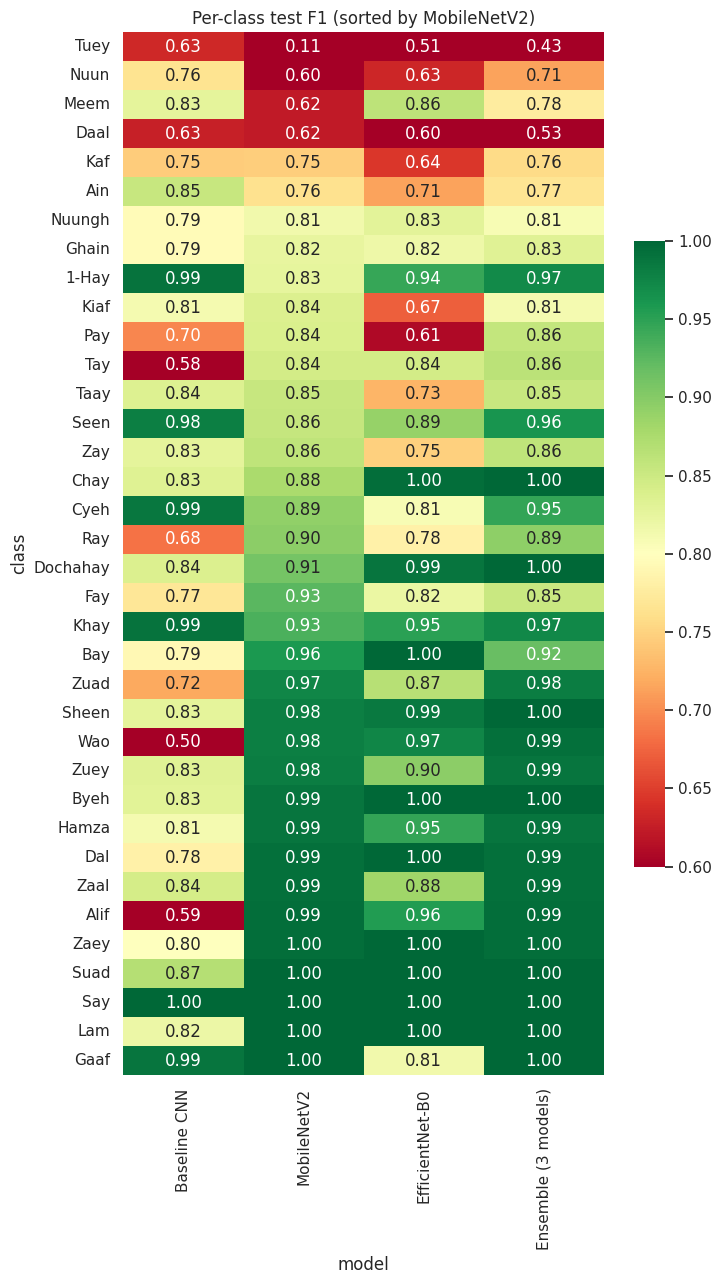

Weakest 8 classes for MobileNetV2


,model,class,precision,recall,f1,support
65,MobileNetV2,Tuey,0.207,0.074,0.109,81
55,MobileNetV2,Nuun,0.971,0.434,0.600,76
54,MobileNetV2,Meem,0.452,1.000,0.623,76
43,MobileNetV2,Daal,0.519,0.779,0.623,104
50,MobileNetV2,Kaf,0.600,0.987,0.746,79
37,MobileNetV2,Ain,0.617,1.000,0.763,79
56,MobileNetV2,Nuungh,1.000,0.688,0.815,80
48,MobileNetV2,Ghain,1.000,0.700,0.824,80


In [9]:
pc = []
for name in SINGLE + ['Ensemble (3 models)']:
    pr, rc, f1, sup = precision_recall_fscore_support(y_te, PT[name].argmax(1), labels=range(K), zero_division=0)
    pc.append(pd.DataFrame({'model': name, 'class': STATIC, 'precision': pr, 'recall': rc, 'f1': f1, 'support': sup}))
PC = pd.concat(pc, ignore_index=True)
f1_tab = PC.pivot(index='class', columns='model', values='f1')[SINGLE + ['Ensemble (3 models)']].sort_values(PRIMARY)
plt.figure(figsize=(7.5, 13)); sns.heatmap(f1_tab, annot=True, fmt='.2f', cmap='RdYlGn', vmin=.6, vmax=1, cbar_kws={'shrink': .6})
plt.title('Per-class test F1 (sorted by ' + PRIMARY + ')'); plt.tight_layout()
plt.savefig(f'{OUT}/p2_07_per_class_f1.png', dpi=130, bbox_inches='tight'); plt.show()
print('Weakest 8 classes for', PRIMARY); display(PC[PC.model == PRIMARY].sort_values('f1').head(8).round(3))

**What it tells us:** a few letters carry most of the errors. Rows that are weak for *every* model point to signs that are genuinely hard to tell apart (a data property), while rows weak for only one model point to that model's weakness.

## 5. Confusion matrix and most confused letters (primary model)

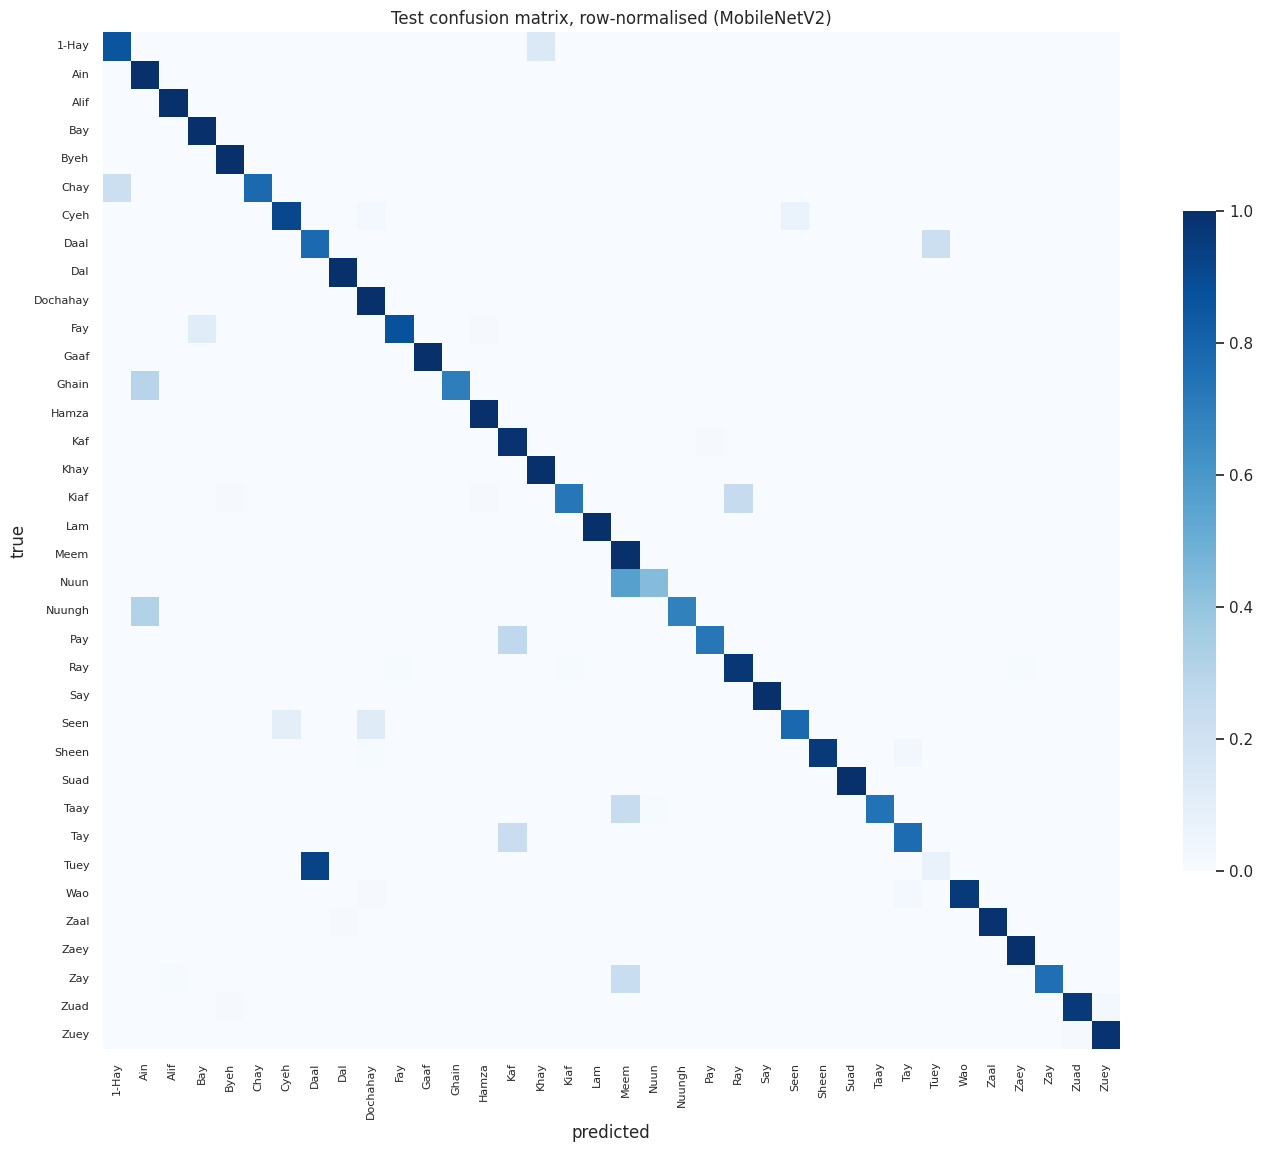

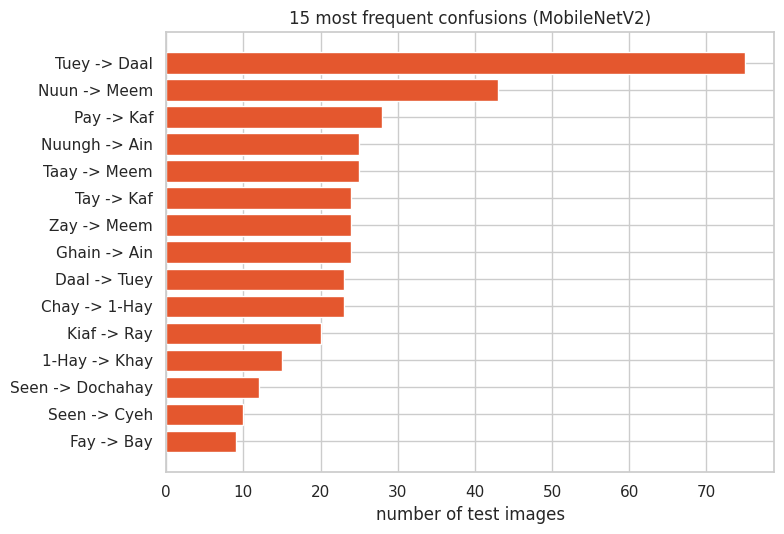

Test errors: 408 of 3238


,true,predicted,count,share_of_true_class
0,Tuey,Daal,75,0.926
1,Nuun,Meem,43,0.566
2,Pay,Kaf,28,0.272
3,Nuungh,Ain,25,0.312
4,Taay,Meem,25,0.245
5,Tay,Kaf,24,0.233
6,Zay,Meem,24,0.235
7,Ghain,Ain,24,0.300
8,Daal,Tuey,23,0.221
9,Chay,1-Hay,23,0.221


In [10]:
pred_p = PT[PRIMARY].argmax(1); cm = confusion_matrix(y_te, pred_p, labels=range(K)); cmn = cm / cm.sum(1, keepdims=True)
plt.figure(figsize=(14, 12)); sns.heatmap(cmn, xticklabels=STATIC, yticklabels=STATIC, cmap='Blues', vmin=0, vmax=1, square=True, cbar_kws={'shrink': .6})
plt.xlabel('predicted'); plt.ylabel('true'); plt.title(f'Test confusion matrix, row-normalised ({PRIMARY})'); plt.xticks(fontsize=8); plt.yticks(fontsize=8)
plt.tight_layout(); plt.savefig(f'{OUT}/p2_06_confusion_matrix.png', dpi=130, bbox_inches='tight'); plt.show()

off = [(STATIC[i], STATIC[j], int(cm[i, j]), cm[i, j] / cm[i].sum()) for i in range(K) for j in range(K) if i != j and cm[i, j] > 0]
CONF = pd.DataFrame(off, columns=['true', 'predicted', 'count', 'share_of_true_class']).sort_values('count', ascending=False).reset_index(drop=True)
top = CONF.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 5.5)); ax.barh([f'{a} -> {b}' for a, b in zip(top['true'], top['predicted'])], top['count'], color='#E4572E')
ax.set_xlabel('number of test images'); ax.set_title(f'15 most frequent confusions ({PRIMARY})'); plt.tight_layout()
plt.savefig(f'{OUT}/p2_08_top_confusions.png', dpi=130, bbox_inches='tight'); plt.show()
print('Test errors:', int((pred_p != y_te).sum()), 'of', len(y_te)); CONF.head(15).round(3)

**What it tells us:** the diagonal is strong, and the off-diagonal cells show which letters are mistaken for which. Pairs that appear here and also looked alike in the EDA mean-image similarity are errors caused by the signs themselves, which no amount of tuning will fully remove.

## 6. The mistakes themselves: most confident errors

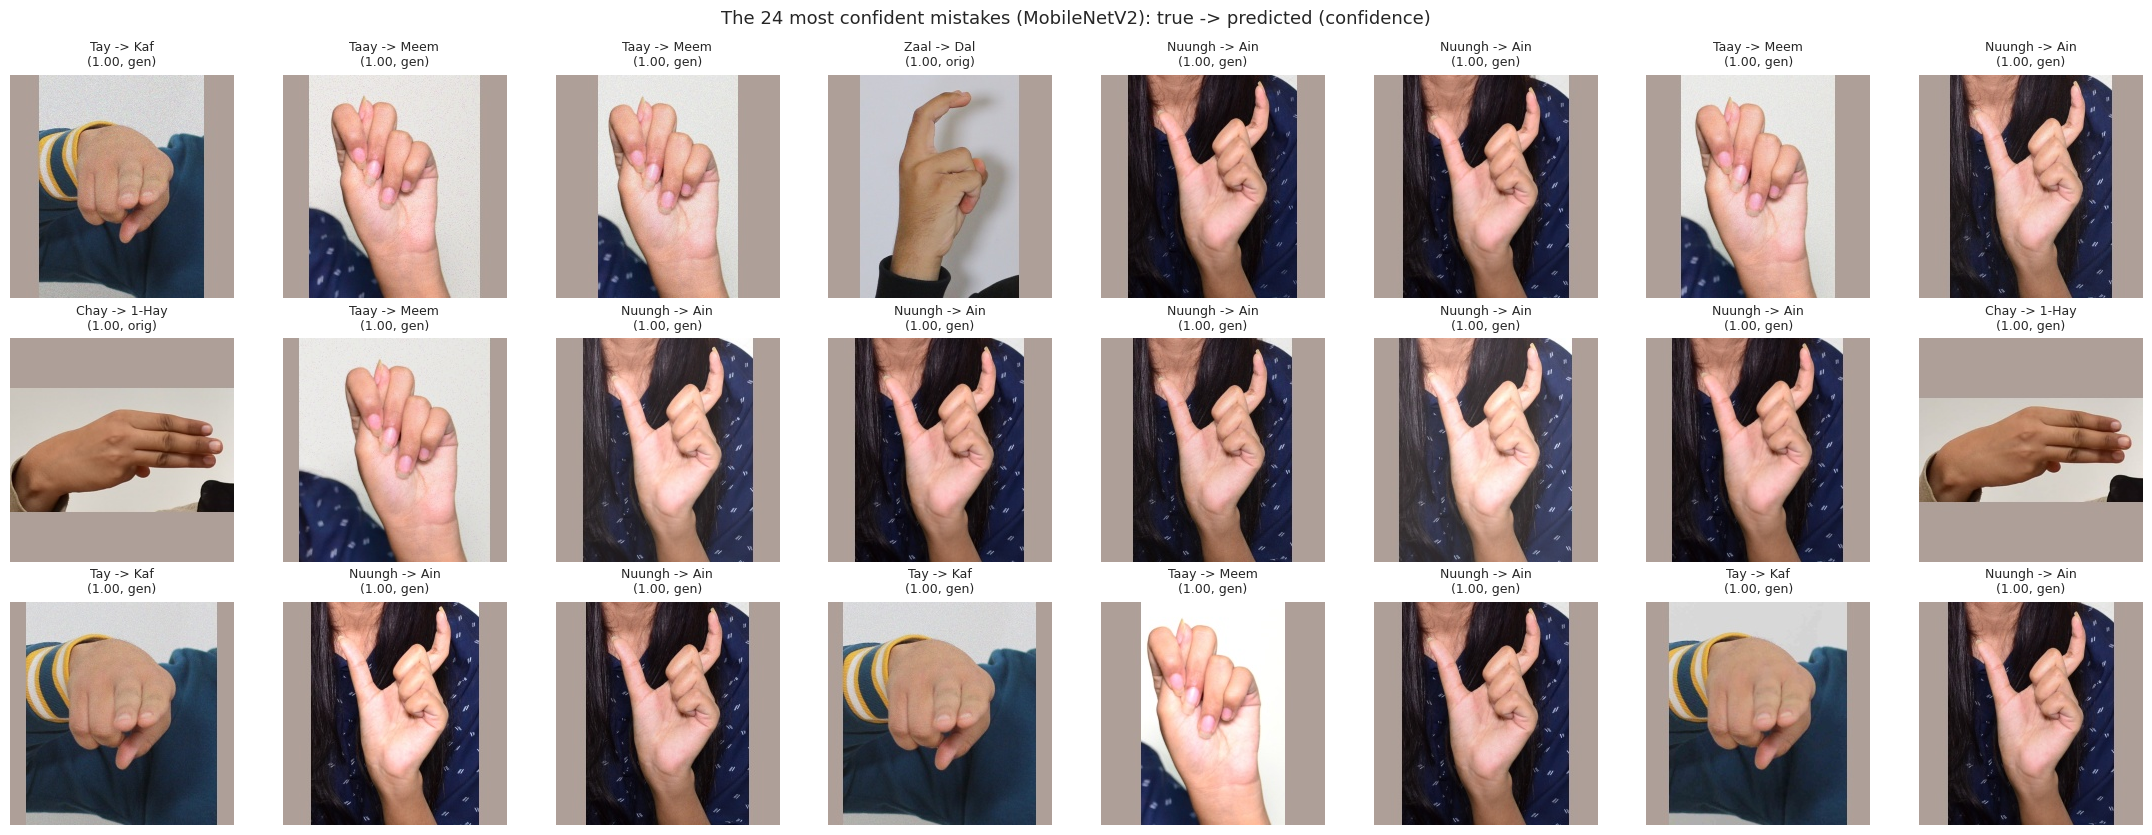

In [11]:
conf = PT[PRIMARY].max(1); wrong = np.where(pred_p != y_te)[0]
worst = wrong[np.argsort(-conf[wrong])][:24]
fig, axes = plt.subplots(3, 8, figsize=(22, 8.5))
for ax, i in zip(axes.ravel(), worst):
    ax.imshow(X_te[i]); ax.axis('off'); ax.set_title(f'{STATIC[y_te[i]]} -> {STATIC[pred_p[i]]}\n({conf[i]:.2f}, {"orig" if te_orig[i] else "gen"})', fontsize=9)
plt.suptitle(f'The 24 most confident mistakes ({PRIMARY}): true -> predicted (confidence)', fontsize=13); plt.tight_layout()
plt.savefig(f'{OUT}/p2_09_error_examples.png', dpi=120, bbox_inches='tight'); plt.show()

**What it tells us:** by looking at the images we can tell whether a confident mistake is a model error, a very similar sign, a poor photo, or even a wrongly labelled image.

## 7. Confidence analysis (sets the threshold for the real-time pipeline)
In the live system a letter will only be accepted when the model is confident enough. A higher threshold gives fewer wrong letters but rejects more frames. The table and curves below show that trade-off on the test set.

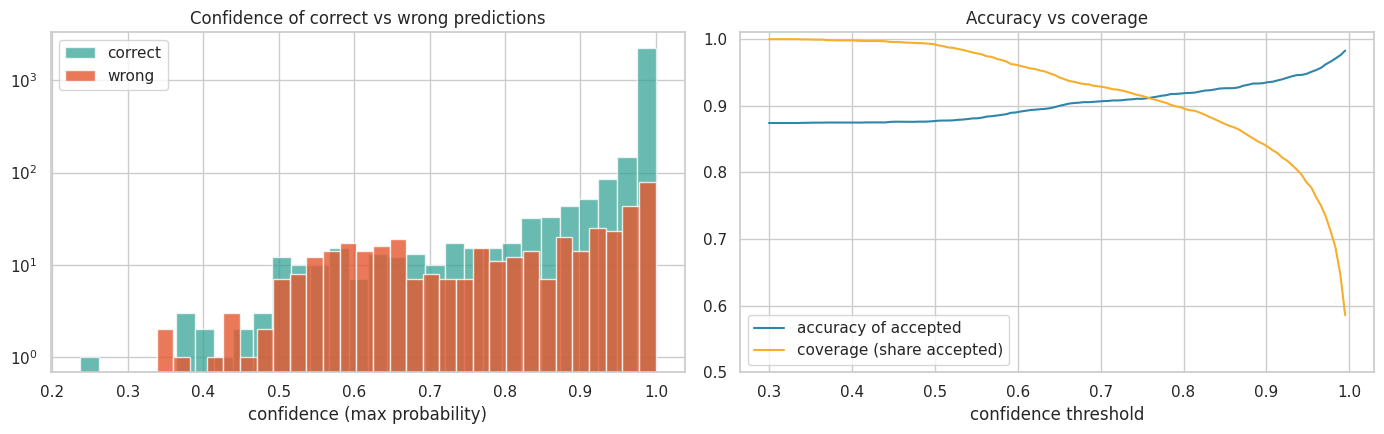

,threshold,coverage,accuracy_of_accepted,wrong_accepted
0,0.50,0.9917,0.8773,394
1,0.70,0.9290,0.9062,282
2,0.80,0.8959,0.9186,236
3,0.90,0.8397,0.9345,178
4,0.95,0.7826,0.9495,128
5,0.99,0.6411,0.9774,47


Mean confidence: correct 0.965 | wrong 0.809


In [12]:
correct = pred_p == y_te
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].hist(conf[correct], bins=30, alpha=.7, label='correct', color='#2A9D8F'); axes[0].hist(conf[~correct], bins=30, alpha=.8, label='wrong', color='#E4572E')
axes[0].set_yscale('log'); axes[0].set_xlabel('confidence (max probability)'); axes[0].set_title('Confidence of correct vs wrong predictions'); axes[0].legend()
ts = np.linspace(0.3, 0.995, 120); cov = [(conf >= t).mean() for t in ts]; acc_t = [correct[conf >= t].mean() if (conf >= t).any() else np.nan for t in ts]
axes[1].plot(ts, acc_t, label='accuracy of accepted', color='#2E86AB'); axes[1].plot(ts, cov, label='coverage (share accepted)', color='#F6AE2D')
axes[1].set_xlabel('confidence threshold'); axes[1].set_title('Accuracy vs coverage'); axes[1].legend(); axes[1].set_ylim(.5, 1.01)
plt.tight_layout(); plt.savefig(f'{OUT}/p2_10_confidence_analysis.png', dpi=130, bbox_inches='tight'); plt.show()
TH = pd.DataFrame([{'threshold': t, 'coverage': (conf >= t).mean(), 'accuracy_of_accepted': correct[conf >= t].mean(), 'wrong_accepted': int((~correct[conf >= t]).sum())}
                   for t in [0.5, 0.7, 0.8, 0.9, 0.95, 0.99]]); display(TH.round(4))
print('Mean confidence: correct', round(conf[correct].mean(), 3), '| wrong', round(conf[~correct].mean(), 3))

## 8. Where do errors come from? (person, original vs generated, brightness, sharpness)

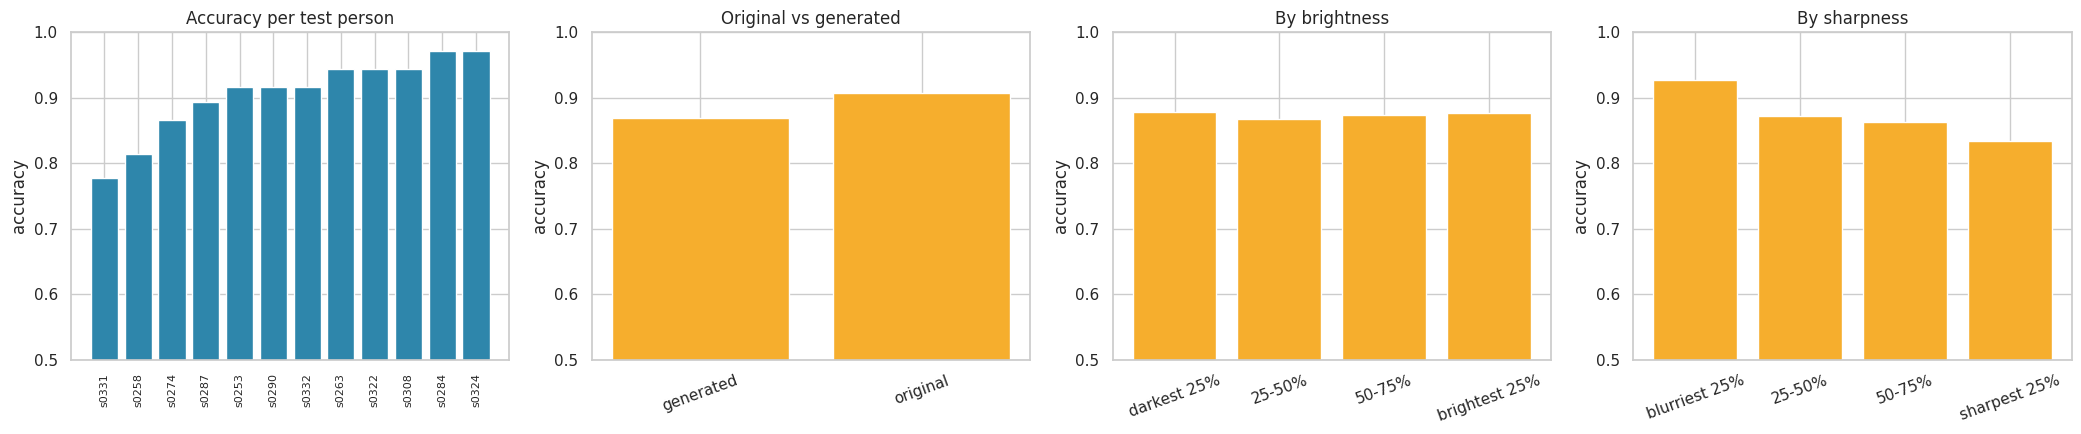

Per-person accuracy (min / median / max): 0.778 0.917 0.972
{'generated': 0.8689, 'original': 0.907}


In [13]:
bright = X_te.mean(axis=(1, 2, 3))
sharp = np.array([cv2.Laplacian(cv2.cvtColor(x, cv2.COLOR_RGB2GRAY), cv2.CV_64F).var() for x in X_te])
d = pd.DataFrame({'correct': correct, 'subject': subj_te, 'original': np.where(te_orig, 'original', 'generated'),
                  'brightness_q': pd.qcut(bright, 4, labels=['darkest 25%', '25-50%', '50-75%', 'brightest 25%']),
                  'sharpness_q': pd.qcut(sharp, 4, labels=['blurriest 25%', '25-50%', '50-75%', 'sharpest 25%'])})
fig, axes = plt.subplots(1, 4, figsize=(21, 4.5))
s = d.groupby('subject')['correct'].mean().sort_values(); axes[0].bar(range(len(s)), s.values, color='#2E86AB'); axes[0].set_xticks(range(len(s))); axes[0].set_xticklabels(s.index, rotation=90, fontsize=8)
axes[0].set_ylim(.5, 1); axes[0].set_title('Accuracy per test person')
for ax, col, t in zip(axes[1:], ['original', 'brightness_q', 'sharpness_q'], ['Original vs generated', 'By brightness', 'By sharpness']):
    g = d.groupby(col)['correct'].mean(); ax.bar(g.index.astype(str), g.values, color='#F6AE2D'); ax.set_ylim(.5, 1); ax.set_title(t); ax.tick_params(axis='x', rotation=20)
for ax in axes: ax.set_ylabel('accuracy')
plt.tight_layout(); plt.savefig(f'{OUT}/p2_11_error_by_factor.png', dpi=130, bbox_inches='tight'); plt.show()
print('Per-person accuracy (min / median / max):', round(s.min(), 3), round(s.median(), 3), round(s.max(), 3))
print(d.groupby('original')['correct'].mean().round(4).to_dict())

**What it tells us:** if accuracy differs strongly between people, the main limit is generalising to new signers (more training people or stronger augmentation would help most). If accuracy drops in the darkest or blurriest quartile, image quality in live use will matter.

## 9. Do the models make the same mistakes? (ensemble check)

In [14]:
errs = {n: (PT[n].argmax(1) != y_te) for n in SINGLE}; E = np.stack([errs[n] for n in SINGLE])
all3 = E.all(0); any1 = E.any(0); ens_wrong = PT['Ensemble (3 models)'].argmax(1) != y_te
print('Test images wrong for ANY model :', int(any1.sum()), f'({any1.mean():.1%})')
print('Test images wrong for ALL models:', int(all3.sum()), f'({all3.mean():.1%})   <- hard samples no model gets right')
print('Ensemble errors:', int(ens_wrong.sum()), f'({ens_wrong.mean():.1%})   vs best single model:', int(min(e.sum() for e in errs.values())))
print('Hard samples by class (top 8):'); print(pd.Series(np.array(STATIC)[y_te[all3]]).value_counts().head(8).to_string())

Test images wrong for ANY model : 1020 (31.5%)
Test images wrong for ALL models: 136 (4.2%)   <- hard samples no model gets right
Ensemble errors: 329 (10.2%)   vs best single model: 408
Hard samples by class (top 8):
Zay       25
Taay      24
Tay       24
Nuungh    22
Kiaf      21
Fay       10
Tuey       3
Daal       2


**What it tells us:** if most errors are shared by all three models, they come from the data (similar signs, unusual images) and a bigger model will not fix them. If the models fail on different images, ensembling or better training can help.

## 10. Save results

In [15]:
MT = M[M.split == 'test'].copy(); MT.to_csv(f'{OUT}/static_results_test.csv', index=False)
M.to_csv(f'{OUT}/static_results_val_test_all.csv', index=False); PC.to_csv(f'{OUT}/static_per_class_test.csv', index=False)
DIFF.to_csv(f'{OUT}/static_bootstrap_diffs.csv', index=False); CI.to_csv(f'{OUT}/static_bootstrap_ci.csv', index=False)
info_df.to_csv(f'{OUT}/static_model_speed_size.csv', index=False); TH.to_csv(f'{OUT}/static_confidence_thresholds.csv', index=False)
np.savez_compressed(f'{OUT}/static_test_predictions.npz', **{n.replace(' ', '_'): PT[n].astype('float16') for n in PT}, y=y_te, subject=subj_te, original=te_orig)
os.makedirs(f'{DRIVE_DIR}/results', exist_ok=True)
for f in os.listdir(OUT):
    if os.path.isfile(f'{OUT}/{f}'): shutil.copy(f'{OUT}/{f}', f'{DRIVE_DIR}/results/{f}')
print(sorted(os.listdir(OUT)))

['p2_05_static_test_comparison.png', 'p2_06_confusion_matrix.png', 'p2_07_per_class_f1.png', 'p2_08_top_confusions.png', 'p2_09_error_examples.png', 'p2_10_confidence_analysis.png', 'p2_11_error_by_factor.png', 'static_bootstrap_ci.csv', 'static_bootstrap_diffs.csv', 'static_confidence_thresholds.csv', 'static_model_speed_size.csv', 'static_per_class_test.csv', 'static_results_test.csv', 'static_results_val_test_all.csv', 'static_test_predictions.npz']


In [16]:
def hdr(t): print('\n' + '=' * 70 + f'\n{t}\n' + '=' * 70)
hdr('Primary model (best validation macro-F1)'); print(PRIMARY)
for sub in ['all', 'originals only']:
    hdr(f'TEST metrics, {sub}'); print(M[(M.split == "test") & (M.subset == sub)].drop(columns=['split', 'subset']).round(4).to_string(index=False))
hdr('VALIDATION metrics, all'); print(M[(M.split == 'val') & (M.subset == 'all')].drop(columns=['split', 'subset']).round(4).to_string(index=False))
hdr('Bootstrap 95% CI of test accuracy'); print(CI.round(4).to_string(index=False))
hdr('Paired differences'); print(DIFF.round(4).to_string(index=False))
hdr('Size and speed (GPU, compiled)'); print(info_df.to_string(index=False))
hdr('Weakest classes (primary)'); print(PC[PC.model == PRIMARY].sort_values('f1').head(8).round(3).to_string(index=False))
hdr('Top confusions (primary)'); print(CONF.head(12).round(3).to_string(index=False))
hdr('Confidence thresholds (primary)'); print(TH.round(4).to_string(index=False)); print('Mean confidence correct / wrong:', round(conf[correct].mean(), 3), round(conf[~correct].mean(), 3))
hdr('Error factors'); print('Per-person accuracy min/median/max:', round(s.min(), 3), round(s.median(), 3), round(s.max(), 3))
print(d.groupby('original')['correct'].mean().round(4).to_dict()); print(d.groupby('brightness_q')['correct'].mean().round(4).to_dict()); print(d.groupby('sharpness_q')['correct'].mean().round(4).to_dict())
hdr('Shared errors'); print('wrong for any:', int(any1.sum()), '| wrong for all:', int(all3.sum()), '| ensemble wrong:', int(ens_wrong.sum()), '| test size:', len(y_te))
print('Hard samples by class:', pd.Series(np.array(STATIC)[y_te[all3]]).value_counts().head(8).to_dict())


Primary model (best validation macro-F1)
MobileNetV2

TEST metrics, all
              model  accuracy  precision  recall  f1_macro  f1_weighted   top3
       Baseline CNN    0.8051     0.8367  0.8011    0.8019       0.8046 0.9367
        MobileNetV2    0.8740     0.8951  0.8728    0.8690       0.8723 0.9725
    EfficientNet-B0    0.8548     0.8755  0.8544    0.8531       0.8562 0.9768
Ensemble (3 models)    0.8984     0.9143  0.8977    0.8974       0.8998 0.9771

TEST metrics, originals only
              model  accuracy  precision  recall  f1_macro  f1_weighted   top3
       Baseline CNN    0.8558     0.8691  0.8559    0.8570       0.8570 0.9674
        MobileNetV2    0.9070     0.9186  0.9072    0.9042       0.9040 0.9884
    EfficientNet-B0    0.8953     0.9031  0.8958    0.8968       0.8963 0.9837
Ensemble (3 models)    0.9302     0.9348  0.9303    0.9285       0.9284 0.9907

VALIDATION metrics, all
              model  accuracy  precision  recall  f1_macro  f1_weighted   top3
   